In [1]:
parameters_file_path = "/home/matmat/Documents/urban_lab/002_Superresolution/raw_data_mat/006_mouse_long/params.json"

convert_complex = True
interpolate_data = True

In [2]:

import numpy as np
import numba
from scipy.io import loadmat
from scipy.signal import firwin
from numba import cuda, njit, vectorize, float64, int32, float32
import math
import matplotlib.pyplot as plt

import json
import modules.beamformer as bf
import modules.beamformer_gpu as bf_gpu

print(np.__version__)
print(numba.__version__)

cuda.detect()

2.1.3
0.61.0
Found 1 CUDA devices
id 0    b'NVIDIA GeForce RTX 3060 Laptop GPU'                              [SUPPORTED]
                      Compute Capability: 8.6
                           PCI Device ID: 0
                              PCI Bus ID: 1
                                    UUID: GPU-ab07a219-12ec-be5b-c280-77dd81f42933
                                Watchdog: Enabled
             FP32/FP64 Performance Ratio: 32
Summary:
	1/1 devices are supported


True

In [3]:
def load_parameters(json_file_path):
    with open(json_file_path, 'r') as f:
        params = json.load(f)
    return params

def add_extra_params(params):
    
    params["rf"]["upsampled_samples"] = params["rf"]["samples"] + (params["rf"]["interpolation_factor"] - 1) * (params["rf"]["samples"] - 1)
    params["rf"]["upsampled_sampling_rate"] = params["rf"]["sampling_rate"] * params["rf"]["interpolation_factor"] 

    return params

In [4]:
params = load_parameters("/home/matmat/Documents/urban_lab/002_Superresolution/raw_data_mat/006_mouse_long/params.json")
params = add_extra_params(params)

In [5]:
if interpolate_data:
    samples = params["rf"]["upsampled_samples"]
    sampling_rate = params["rf"]["upsampled_sampling_rate"]
else:
    samples = params["rf"]["samples"]
    sampling_rate = params["rf"]["sampling_rate"]
if convert_complex:
    bf_dtype = np.complex64
else:
    bf_dtype = np.float32

In [6]:
beamformer = bf.Beamformer(
    nsi_dc_offset=0.01,
    params=params, 
    sampling_rate = sampling_rate,
    samples=samples,
    using_real_data=True,
    interpolate_data=True,
    bf_dtype=bf_dtype,
    debug=False
    )

In [7]:
# mat = loadmat('/home/matmat/Documents/urban_lab/002_Superresolution/raw_data_mat/006_mouse_long/prebf_filtered/001_rf_IQ_testing.npy')
# mat = list(mat.values())[-1]
mat = np.load('/home/matmat/Documents/urban_lab/002_Superresolution/raw_data_mat/006_mouse_long/prebf_filtered/001_rf_IQ_testing.npy')
# mat = mat[:,:,:,:10].copy()
mat.shape

(1535, 128, 16, 160)

# CPU

In [8]:
# %%time

# mat_bf = beamformer.beamforming(mat[:,:,:,:10], 10, 'rectangle')
# mat_bf = np.sum(mat_bf, axis=2)

In [9]:
# plt.imshow(np.sqrt(np.abs(np.sum(mat_bf, axis=2))), cmap='hot')
# del mat_bf

## GPU

In [10]:
beamformer_gpu = bf_gpu.BeamformerGPU(
    nsi_dc_offset=0.01,
    params=params, 
    sampling_rate = sampling_rate,
    samples=samples,
    using_real_data=True,
    interpolate_data=True,
    bf_dtype=bf_dtype,
    debug=False
    )

In [11]:
%%time 

mat_bf_gpu = beamformer_gpu.beamforming_gpu(mat, 160, 'rectangle')
mat_bf_gpu = np.sum(mat_bf_gpu, axis=2)

CPU times: user 2min 21s, sys: 1.66 s, total: 2min 23s
Wall time: 2min 23s


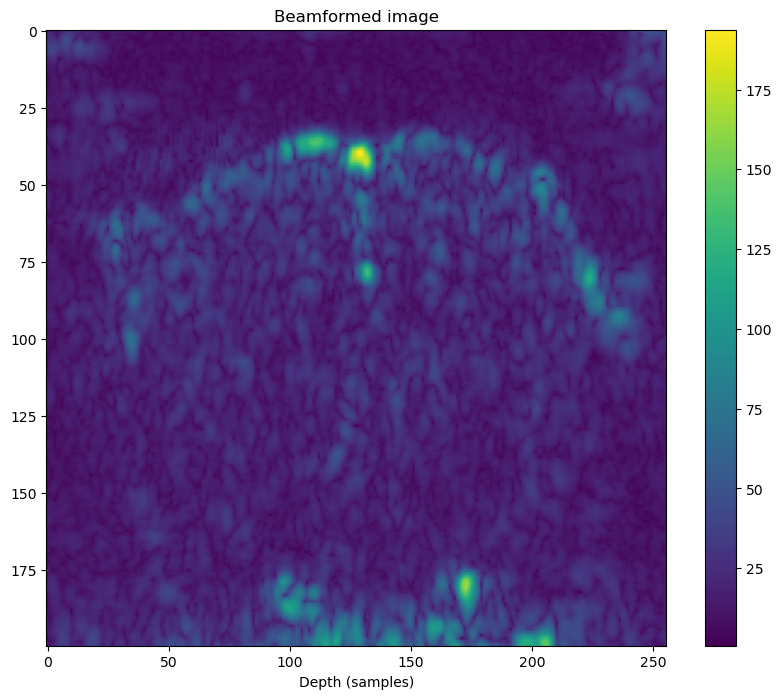

In [12]:
plt.figure(figsize=(10, 8)) 
plt.imshow(np.sqrt(np.abs(np.sum(mat_bf_gpu, axis=2))), aspect='auto', cmap='viridis')
plt.colorbar()
plt.title("Beamformed image")
plt.xlabel("Depth (samples)")
plt.show()